---
title: "Linear Algebra for Mechanics"
short_title: "M6 Linear Algebra"
numbering:
  heading_2: true
  equation: true
---

# Linear Algebra for Mechanics

:::{tip} Where this sits in the plan
Math for **noninertial frames** (rotation matrices), **rigid bodies** (the inertia tensor, principal axes), **normal modes** (eigenvalue problems, systems of linear ODEs) and later **special relativity** (Lorentz matrices).

| Item | Boas | Zill | Arfken |
|---|---|---|---|
| Matrices and determinants | 3 | 8 | 2 |
| Eigenvalues and diagonalization | 3 | 8 | 6 |
| Systems of linear ODEs | 3, 8 | 10 | 7 |
| Tensors | 10 | – | 4 |

Chapter numbers are approximate, as in the workbook.
:::

Exercises have separate hint and answer dropdowns. NumPy and SymPy both do the heavy lifting here; the point is to know what the computations mean.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp, quad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
g = 9.81  # m/s^2

## Matrices as Linear Maps

A matrix $A$ is a rule that turns a vector into another vector, $\mathbf{y} = A\mathbf{x}$, with $y_i = \sum_jA_{ij}x_j$. Linearity means $A(a\mathbf{x} + b\mathbf{z}) = aA\mathbf{x} + bA\mathbf{z}$, so $A$ is completely determined by what it does to the basis vectors: **the columns of $A$ are the images of $\mathbf{e}_1, \mathbf{e}_2, \dots$**.

Products compose maps: $(AB)\mathbf{x} = A(B\mathbf{x})$, apply $B$ first. Composition generally depends on order, so $AB\neq BA$.

### Determinant

$\det A$ is the factor by which $A$ scales areas (2D) or volumes (3D), with a sign that records whether orientation is reversed. Two facts matter most:

- $\det(AB) = \det A\,\det B$.
- $\det A = 0$ exactly when $A$ squashes some nonzero vector to zero. Then $A\mathbf{x} = \mathbf{0}$ has nonzero solutions and $A$ has no inverse.

The second fact is how every eigenvalue and normal-mode problem is solved: a homogeneous system has a nontrivial solution only if its determinant vanishes.

### Transpose, symmetric and orthogonal matrices

- $A^{\mathsf T}$ swaps rows and columns, and $(AB)^{\mathsf T} = B^{\mathsf T}A^{\mathsf T}$.
- $A$ is **symmetric** if $A^{\mathsf T} = A$. Inertia tensors, stiffness matrices and mass matrices are all symmetric.
- $R$ is **orthogonal** if $R^{\mathsf T}R = I$, so $R^{-1} = R^{\mathsf T}$. Orthogonal matrices preserve lengths and angles, and $\det R = \pm1$.

## Rotation Matrices

A rotation is an orthogonal matrix with determinant $+1$. In two dimensions, rotating vectors counterclockwise by $\theta$:

$$
R(\theta) = \begin{pmatrix}\cos\theta & -\sin\theta\\ \sin\theta & \cos\theta\end{pmatrix} .
$$

In three dimensions, rotations about the coordinate axes have the same block, for example $R_z(\theta)$ acting on the $x$ and $y$ components and leaving $z$ alone.

:::{warning} Active versus passive
A matrix can rotate the **vector** (active) or rotate the **axes** while the vector stays put (passive). The two are inverses: rotating the axes by $\theta$ changes a fixed vector's components by $R(-\theta) = R(\theta)^{\mathsf T}$. Most sign errors with rotating frames come from mixing the two. Always say which one you mean.
:::

### Rotations do not commute

Rotating a book $90^\circ$ about $x$ then $90^\circ$ about $y$ leaves it in a different orientation from doing the two in the opposite order. This is why finite rotations cannot be treated as vectors, and why rigid-body motion needs care.

In [2]:
def Rx(t): c, s = np.cos(t), np.sin(t); return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])
def Ry(t): c, s = np.cos(t), np.sin(t); return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])

v = np.array([0, 0, 1.0])
print("x then y:", np.round(Ry(np.pi / 2) @ Rx(np.pi / 2) @ v, 3))
print("y then x:", np.round(Rx(np.pi / 2) @ Ry(np.pi / 2) @ v, 3))
R = Ry(0.3) @ Rx(1.1)
print("orthogonal:", np.allclose(R.T @ R, np.eye(3)), "| det =", round(np.linalg.det(R), 12))

x then y: [ 0. -1.  0.]
y then x: [ 1. -0.  0.]
orthogonal: True | det = 1.0


### Small rotations and the angular-velocity matrix

For a tiny angle $d\theta$ about the $z$-axis, $\cos d\theta\approx1$ and $\sin d\theta\approx d\theta$, so

$$
R_z(d\theta)\,\mathbf{r}\approx\mathbf{r} + d\theta\,\hat{\mathbf{z}}\times\mathbf{r} .
$$

Small rotations **do** commute (to first order) and add like vectors. Dividing by $dt$ gives the rotating-vector formula from M1: a vector carried along by a rotation with angular velocity $\boldsymbol\omega$ changes as

$$
\dot{\mathbf{r}} = \boldsymbol\omega\times\mathbf{r} = \Omega\,\mathbf{r}, \qquad
\Omega = \begin{pmatrix}0 & -\omega_z & \omega_y\\ \omega_z & 0 & -\omega_x\\ -\omega_y & \omega_x & 0\end{pmatrix} .
$$ (eq-omega-matrix)

The cross product with $\boldsymbol\omega$ is a multiplication by an **antisymmetric** matrix. This is the bridge between the noninertial-frames notes and rigid-body rotation.

### Exercises

1. Show that $R(\theta)$ in 2D is orthogonal and that $R(\alpha)R(\beta) = R(\alpha + \beta)$.
2. Compute $\det$ of $\begin{pmatrix}2 & 1\\ 4 & 2\end{pmatrix}$ and find a nonzero vector it sends to zero.
3. Verify {eq}`eq-omega-matrix` for $\boldsymbol\omega = \langle0, 0, \omega\rangle$ acting on $\mathbf{r} = \langle x, y, z\rangle$.

:::{dropdown} Hints
1. Multiply and use the angle-addition formulas.
2. The second row is twice the first.
3. Compare $\Omega\mathbf{r}$ with $\boldsymbol\omega\times\mathbf{r}$ from {eq}`eq-cross` in M1.
:::

:::{dropdown} Answers
1. $R^{\mathsf T}R = I$ by $\cos^2 + \sin^2 = 1$; multiplying out and using the addition formulas gives $R(\alpha + \beta)$. In 2D, rotations do commute.
2. $\det = 0$; $\langle1, -2\rangle$ is sent to zero.
3. Both give $\langle-\omega y, \omega x, 0\rangle$.
:::

## Eigenvalues and Eigenvectors

An **eigenvector** of $A$ is a nonzero vector that $A$ only stretches:

$$
A\mathbf{v} = \lambda\mathbf{v} .
$$

Rewriting as $(A - \lambda I)\mathbf{v} = \mathbf{0}$ and requiring a nonzero solution gives the **characteristic equation** $\det(A - \lambda I) = 0$, a polynomial whose roots are the eigenvalues. For each eigenvalue, solve the (singular) linear system for $\mathbf{v}$.

:::{prf:theorem} Symmetric matrices
:label: thm-spectral

A real symmetric matrix has real eigenvalues, and eigenvectors for different eigenvalues are orthogonal. It can always be **diagonalized** by a rotation:

$$
A = Q\,\Lambda\,Q^{\mathsf T},
$$

where the columns of the orthogonal matrix $Q$ are orthonormal eigenvectors and $\Lambda$ is diagonal with the eigenvalues.
:::

Geometrically, a symmetric matrix stretches space along a set of perpendicular axes, its eigenvectors, by factors equal to its eigenvalues. In the eigenvector basis, it is just a list of stretches. Finding that basis is what "principal axes" means for a rigid body and what "normal modes" means for coupled oscillators.

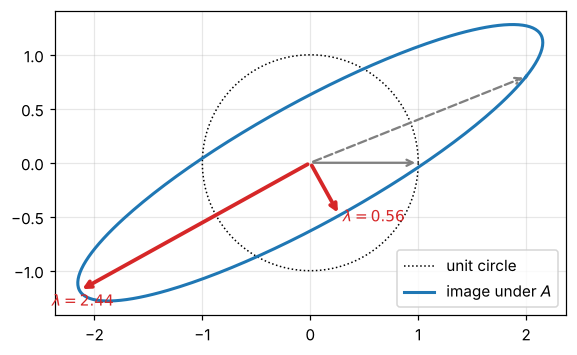

In [3]:
#| label: fig-eigen-ellipse
#| caption: A symmetric matrix maps the unit circle to an ellipse. The ellipse's axes lie along the eigenvectors (red), with semi-axis lengths equal to the eigenvalues. A vector along an eigenvector (red) only stretches; other vectors (gray) also turn.
A = np.array([[2.0, 0.8], [0.8, 1.0]])
lam, Q = np.linalg.eigh(A)
t = np.linspace(0, 2 * np.pi, 300)
circle = np.vstack([np.cos(t), np.sin(t)])
img = A @ circle
fig, ax = plt.subplots(figsize=(6, 5.4))
ax.plot(*circle, "k:", lw=1, label="unit circle")
ax.plot(*img, "tab:blue", lw=2, label=r"image under $A$")
for k in range(2):
    v = Q[:, k]
    ax.annotate("", xy=lam[k] * v, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="tab:red", lw=2.5))
    ax.text(*(lam[k] * v * 1.12), rf"$\lambda = {lam[k]:.2f}$", color="tab:red")
u = np.array([1.0, 0.0])
ax.annotate("", xy=u, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="gray", lw=1.5))
ax.annotate("", xy=A @ u, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="gray", lw=1.5, ls="--"))
ax.set_aspect("equal"); ax.legend(loc="lower right"); plt.show()

In [4]:
# Diagonalization, symbolically and numerically
A = sp.Matrix([[2, 1, 0], [1, 2, 1], [0, 1, 2]])
print("eigenvalues:", A.eigenvals())
P, D = A.diagonalize(normalize=True)
print("D =", D)
print("P^T A P == D:", sp.simplify(P.T * A * P - D) == sp.zeros(3, 3))

eigenvalues: {2: 1, 2 - sqrt(2): 1, sqrt(2) + 2: 1}
D = Matrix([[2, 0, 0], [0, 2 - sqrt(2), 0], [0, 0, sqrt(2) + 2]])
P^T A P == D: True


### The generalized eigenvalue problem

Normal-mode problems lead to $K\mathbf{a} = \lambda M\mathbf{a}$ with two symmetric matrices, the stiffness $K$ and the mass $M$ (positive definite). The condition is $\det(K - \lambda M) = 0$. The eigenvectors are orthogonal **with respect to $M$** ($\mathbf{a}_i^{\mathsf T}M\mathbf{a}_j = 0$ for $i\ne j$), and `scipy.linalg.eigh(K, M)` solves it directly.

### Exercises

1. Find the eigenvalues and eigenvectors of $\begin{pmatrix}3 & 1\\ 1 & 3\end{pmatrix}$.
2. Show that the eigenvalues of a 2D rotation matrix are $e^{\pm i\theta}$. Why can there be no real eigenvector (unless $\theta = 0$ or $\pi$)?
3. Show that eigenvectors of a symmetric matrix with distinct eigenvalues are orthogonal.

:::{dropdown} Hints
1. $\det(A - \lambda I) = (3 - \lambda)^2 - 1$.
2. The characteristic equation is $\lambda^2 - 2\lambda\cos\theta + 1 = 0$.
3. Compute $\mathbf{v}_1^{\mathsf T}A\mathbf{v}_2$ two ways.
:::

:::{dropdown} Answers
1. $\lambda = 4$ with $\langle1,1\rangle$ and $\lambda = 2$ with $\langle1,-1\rangle$.
2. $\lambda = \cos\theta\pm i\sin\theta$. A rotation changes the direction of every vector in the plane, so no real vector is merely stretched.
3. $\mathbf{v}_1^{\mathsf T}A\mathbf{v}_2 = \lambda_2\mathbf{v}_1\cdot\mathbf{v}_2$, and also $= (A\mathbf{v}_1)^{\mathsf T}\mathbf{v}_2 = \lambda_1\mathbf{v}_1\cdot\mathbf{v}_2$. With $\lambda_1\ne\lambda_2$, $\mathbf{v}_1\cdot\mathbf{v}_2 = 0$.
:::

## Systems of Linear ODEs

A first-order linear system $\dot{\mathbf{x}} = A\mathbf{x}$ is solved by eigenvectors. If $A\mathbf{v}_k = \lambda_k\mathbf{v}_k$, then $\mathbf{v}_ke^{\lambda_kt}$ is a solution, and the general solution is

$$
\mathbf{x}(t) = \sum_k c_k\,\mathbf{v}_k\,e^{\lambda_kt} .
$$ (eq-linear-system)

In the eigenvector basis the equations **decouple** into independent one-variable equations. That is the whole idea of normal modes. (Formally, $\mathbf{x}(t) = e^{At}\mathbf{x}(0)$ with the matrix exponential.)

In two dimensions, the eigenvalues fix the shape of every trajectory near the origin:

| Eigenvalues | Name | Behavior |
|---|---|---|
| real, both negative | stable node | everything flows in |
| real, opposite signs | saddle | in along one eigenvector, out along the other |
| complex, negative real part | stable spiral | spirals in (damped oscillator) |
| purely imaginary | center | closed orbits (undamped oscillator) |

A second-order system $M\ddot{\mathbf{x}} = -K\mathbf{x}$ is handled by guessing $\mathbf{x} = \mathbf{a}\cos(\omega t - \delta)$, which gives the generalized eigenproblem $K\mathbf{a} = \omega^2M\mathbf{a}$.

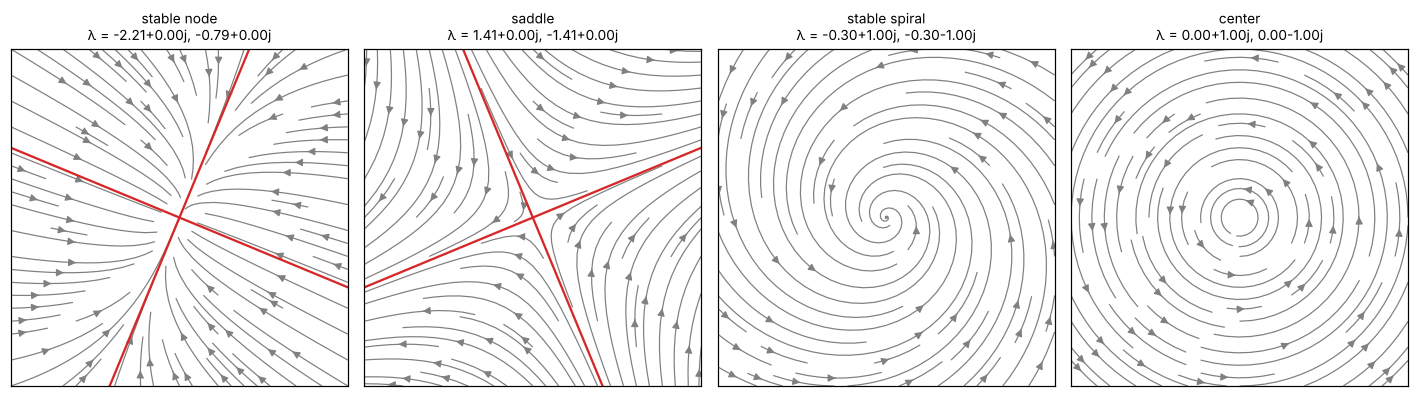

In [5]:
#| label: fig-phase-portraits
#| caption: Phase portraits of ẋ = Ax for four matrices. The eigenvalues decide the picture; red lines mark real eigenvector directions.
mats = {"stable node": [[-2, 0.5], [0.5, -1]], "saddle": [[1, 1], [1, -1]],
        "stable spiral": [[-0.3, -1], [1, -0.3]], "center": [[0, -1], [1, 0]]}
g1 = np.linspace(-2, 2, 25)
X, Y = np.meshgrid(g1, g1)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, (name, A) in zip(axes, mats.items()):
    A = np.array(A, float)
    U, V = A[0, 0] * X + A[0, 1] * Y, A[1, 0] * X + A[1, 1] * Y
    ax.streamplot(X, Y, U, V, density=0.9, color="gray", linewidth=0.8)
    lam, vecs = np.linalg.eig(A)
    if np.all(np.isreal(lam)):
        for k in range(2):
            v = np.real(vecs[:, k]) * 3
            ax.plot([-v[0], v[0]], [-v[1], v[1]], "tab:red", lw=1.5)
    ax.set_title(f"{name}\nλ = " + ", ".join(f"{l:.2f}" for l in lam), fontsize=9)
    ax.set_xlim(-2, 2); ax.set_ylim(-2, 2); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### Exercises

1. Write the damped oscillator $\ddot x + 2\beta\dot x + \omega_0^2x = 0$ as a system $\dot{\mathbf{x}} = A\mathbf{x}$ with $\mathbf{x} = \langle x, \dot x\rangle$, and show that the eigenvalues of $A$ are the roots of the characteristic equation in M4.
2. Solve $\dot x = x + y$, $\dot y = x - y$ with $x(0) = 1$, $y(0) = 0$.

:::{dropdown} Hints
1. $A = \begin{pmatrix}0 & 1\\ -\omega_0^2 & -2\beta\end{pmatrix}$.
2. The eigenvalues are $\pm\sqrt2$; decompose the initial condition into eigenvectors.
:::

:::{dropdown} Answers
1. $\det(A - \lambda I) = \lambda^2 + 2\beta\lambda + \omega_0^2$, the same polynomial.
2. $x = \cosh\sqrt2t + \tfrac{1}{\sqrt2}\sinh\sqrt2t$, $y = \tfrac{1}{\sqrt2}\sinh\sqrt2t$.
:::

## Tensors

A **second-rank tensor** in this course is a linear rule that turns one vector into another, like the inertia tensor turning angular velocity into angular momentum, $\mathbf{L} = I\boldsymbol\omega$. In a given basis it is written as a $3\times3$ matrix.

What makes it a tensor rather than just a table of nine numbers is how it **transforms**. If the axes are rotated by $R$, vectors transform as $\mathbf{x}' = R\mathbf{x}$, and for $\mathbf{L} = I\boldsymbol\omega$ to keep the same form in the new axes, the matrix must transform as

$$
I' = R\,I\,R^{\mathsf T}, \qquad I'_{ij} = \sum_{k,l}R_{ik}R_{jl}I_{kl} .
$$ (eq-tensor-transform)

Each index transforms like a vector index. The spectral theorem says that for a symmetric tensor some rotation makes $I'$ diagonal: those axes are the **principal axes**.

Quantities that do not change under rotation are physically meaningful in any frame. For a symmetric tensor, the **trace** $\sum_iI_{ii}$, the **determinant**, and the eigenvalues are all invariant.

:::{note} Where tensors appear
Inertia tensor (rigid bodies), stress and strain (elasticity), the quadrupole moment (E&M), the electromagnetic field tensor and the metric (relativity). The same transformation rule {eq}`eq-tensor-transform` covers all of them, with $R$ replaced by a Lorentz transformation in relativity.
:::

In [6]:
# A symmetric tensor in rotated axes: components change, invariants do not
T = np.array([[4.0, 1.0, 0.5], [1.0, 3.0, 0.0], [0.5, 0.0, 2.0]])
R = Ry(0.7) @ Rx(-0.4)
Tp = R @ T @ R.T
print("rotated components:\n", np.round(Tp, 3))
print("trace  :", round(np.trace(T), 6), round(np.trace(Tp), 6))
print("det    :", round(np.linalg.det(T), 6), round(np.linalg.det(Tp), 6))
print("eigvals:", np.round(np.linalg.eigvalsh(T), 6), np.round(np.linalg.eigvalsh(Tp), 6))

rotated components:
 [[ 3.303  0.622 -0.899]
 [ 0.622  2.848 -0.993]
 [-0.899 -0.993  2.849]]
trace  : 9.0 9.0
det    : 21.25 21.25
eigvals: [1.813859 2.5      4.686141] [1.813859 2.5      4.686141]


### Exercises

1. Show that the trace of a matrix is unchanged by $T\to RTR^{\mathsf T}$ for orthogonal $R$.
2. A quadratic form $Q = \mathbf{x}^{\mathsf T}A\mathbf{x}$ with symmetric $A$. Show that in the eigenvector basis it becomes $\sum\lambda_iy_i^2$. What does this say about the shape of the surface $Q = 1$ when all $\lambda_i > 0$?

:::{dropdown} Hints
1. Use $\operatorname{tr}(ABC) = \operatorname{tr}(CAB)$.
2. Substitute $\mathbf{x} = Q\mathbf{y}$ with $A = Q\Lambda Q^{\mathsf T}$.
:::

:::{dropdown} Answers
1. $\operatorname{tr}(RTR^{\mathsf T}) = \operatorname{tr}(R^{\mathsf T}RT) = \operatorname{tr}T$.
2. $Q = \mathbf{y}^{\mathsf T}\Lambda\mathbf{y} = \sum\lambda_iy_i^2$. With all $\lambda_i > 0$, $Q = 1$ is an ellipsoid with semi-axes $1/\sqrt{\lambda_i}$ along the eigenvectors (the inertia ellipsoid is an example).
:::

## Summary

- Matrices are linear maps; columns are the images of the basis vectors; products compose maps and usually do not commute.
- $\det = 0$ is the condition for a homogeneous system to have a nonzero solution.
- Rotations are orthogonal with $\det = +1$. Finite rotations do not commute; infinitesimal ones are cross products with $\boldsymbol\omega$.
- Real symmetric matrices have real eigenvalues and orthogonal eigenvectors, and are diagonalized by a rotation.
- Linear ODE systems decouple in the eigenvector basis, and the eigenvalues classify the phase portrait.
- A tensor is a matrix that transforms as $RTR^{\mathsf T}$; its trace, determinant and eigenvalues are invariant.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.